Mount Google Drive and set the dataset path

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

# Change this to the folder containing seg_train, seg_test and seg_pred.
DATA_ROOT = Path("/content/drive/MyDrive/archive (8)")

print("DATA_ROOT:", DATA_ROOT)
print("Exists:", DATA_ROOT.exists())
if DATA_ROOT.exists():
    print("Top-level contents:", [p.name for p in DATA_ROOT.iterdir()])
else:
    raise FileNotFoundError("Update DATA_ROOT to your actual extracted dataset folder.")

Mounted at /content/drive
DATA_ROOT: /content/drive/MyDrive/archive (8)
Exists: True
Top-level contents: ['seg_train', 'seg_test', 'seg_pred']


1. Dataset acquisition

Find the correct labelled directories.

What this cell does: defines the six expected class names and the allowed image extensions. The function find_split_class_root searches DATA_ROOT for the folder that directly contains all six class folders, for seg_train, seg_test and seg_pred. It picks the shortest matching path.

Why: the Kaggle archive can be extracted with extra nested folders. Searching for the folders makes the notebook work regardless of nesting, and it makes sure I use the labelled seg_train and seg_test folders. seg_pred has no labels, so it is found but never used for training or scoring.

In [3]:
EXPECTED_CLASSES = {"buildings", "forest", "glacier", "mountain", "sea", "street"}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_split_class_root(root, split_name):
    """Find the directory directly containing all six class folders."""
    if not root.exists():
        return None
    candidates = []
    for p in root.rglob("*"):
        if not p.is_dir() or split_name not in str(p).lower():
            continue
        try:
            names = {x.name.lower() for x in p.iterdir() if x.is_dir()}
        except PermissionError:
            continue
        if EXPECTED_CLASSES.issubset(names):
            candidates.append(p)
    # Prefer the shortest path containing all classes
    return min(candidates, key=lambda p: len(p.parts)) if candidates else None

TRAIN_DIR = find_split_class_root(DATA_ROOT, "seg_train")
TEST_DIR = find_split_class_root(DATA_ROOT, "seg_test")
PRED_DIR = find_split_class_root(DATA_ROOT, "seg_pred")

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)
print("PRED_DIR :", PRED_DIR)

TRAIN_DIR: /content/drive/MyDrive/archive (8)/seg_train/seg_train
TEST_DIR : /content/drive/MyDrive/archive (8)/seg_test/seg_test
PRED_DIR : None


2. (EDA) Data inspection: counts by class and image validity

In [4]:
import pandas as pd
import numpy as np
from PIL import Image, ImageFile
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import os, hashlib, random, shutil, time

ImageFile.LOAD_TRUNCATED_IMAGES = False

def inspect_split(split_dir, split_name):
    rows = []
    if split_dir is None:
        return pd.DataFrame(rows)
    for class_dir in sorted([p for p in split_dir.iterdir() if p.is_dir()]):
        for p in class_dir.rglob("*"):
            if not p.is_file() or p.suffix.lower() not in IMAGE_EXTS:
                continue
            row = {
                "split": split_name, "label": class_dir.name,
                "path": str(p), "extension": p.suffix.lower(),
                "bytes": p.stat().st_size, "width": np.nan,
                "height": np.nan, "mode": None, "valid": False,
                "error": None
            }
            try:
                with Image.open(p) as im:
                    im.verify()
                with Image.open(p) as im:
                    row.update(width=im.width, height=im.height, mode=im.mode, valid=True)
            except Exception as e:
                row["error"] = f"{type(e).__name__}: {e}"
            rows.append(row)
    return pd.DataFrame(rows)

train_inspection = inspect_split(TRAIN_DIR, "train")
test_inspection = inspect_split(TEST_DIR, "test")
inspection = pd.concat([train_inspection, test_inspection], ignore_index=True)

print("Total labelled files inspected:", len(inspection))
if inspection.empty:
    raise ValueError("No labelled images found. Correct DATA_ROOT / restore the dataset.")
print("\nCounts by split and class:")
display(pd.crosstab(inspection["split"], inspection["label"]))
print("\nMissing values:")
display(inspection.isna().sum().rename("missing_count").to_frame())
print("\nValidity summary:")
display(inspection.groupby("split")["valid"].agg(["count", "sum"]))
print("\nInvalid files (first 30):")
display(inspection.loc[~inspection["valid"], ["split", "label", "path", "error"]].head(30))
print("\nNumeric summary:")
display(inspection[["bytes", "width", "height"]].describe().round(2))
print("\nFile extensions:")
display(inspection["extension"].value_counts().to_frame("count"))
print("\nImage colour modes:")
display(inspection["mode"].fillna("invalid").value_counts().to_frame("count"))

Total labelled files inspected: 17044

Counts by split and class:


label,buildings,forest,glacier,mountain,sea,street
split,,,,,,
test,437,474,553,525,510,501
train,2191,2271,2414,2512,2274,2382



Missing values:


,missing_count
split,0
label,0
path,0
extension,0
bytes,0
width,0
height,0
mode,0
valid,0
error,17044



Validity summary:


,count,sum
split,,
test,3000,3000
train,14044,14044


... (4 outputs left out)


File extensions:


,count
extension,
.jpg,17044



Image colour modes:


,count
mode,
RGB,17044


3. Detailed EDA visualisations

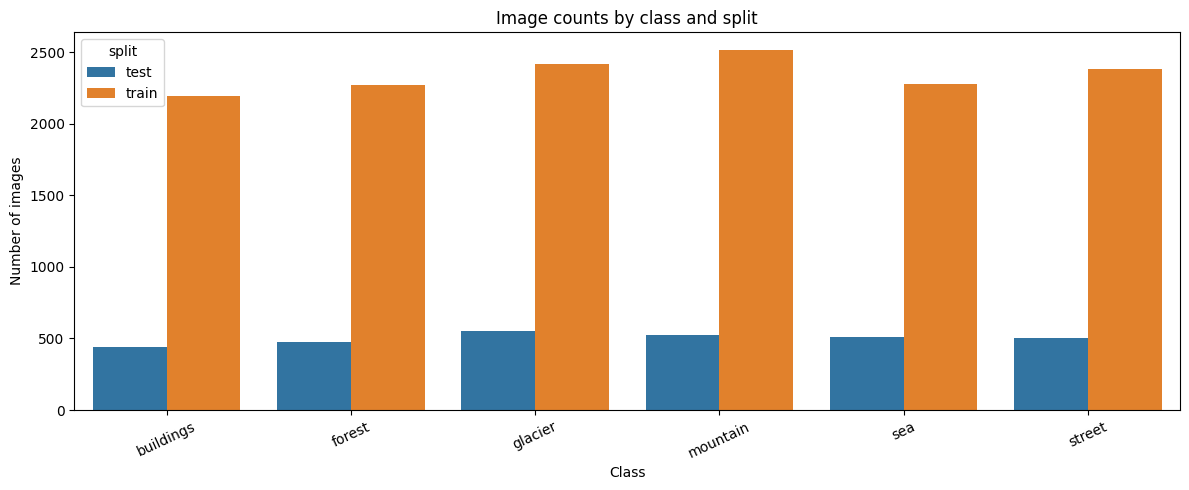

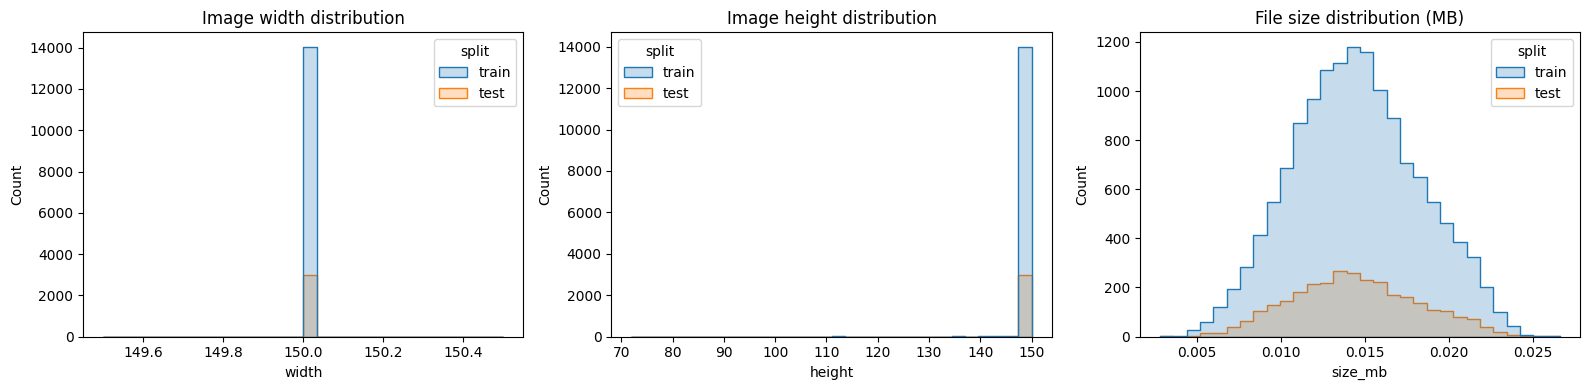

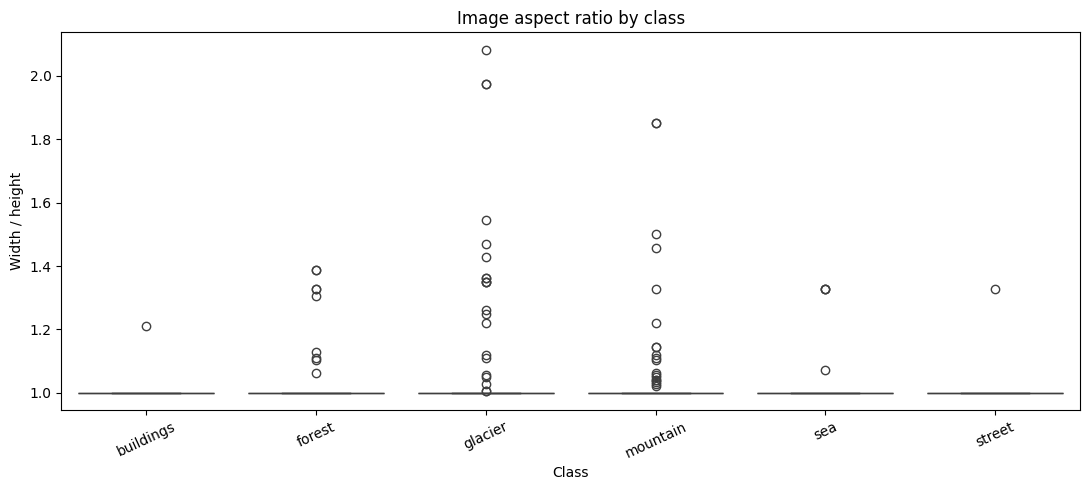

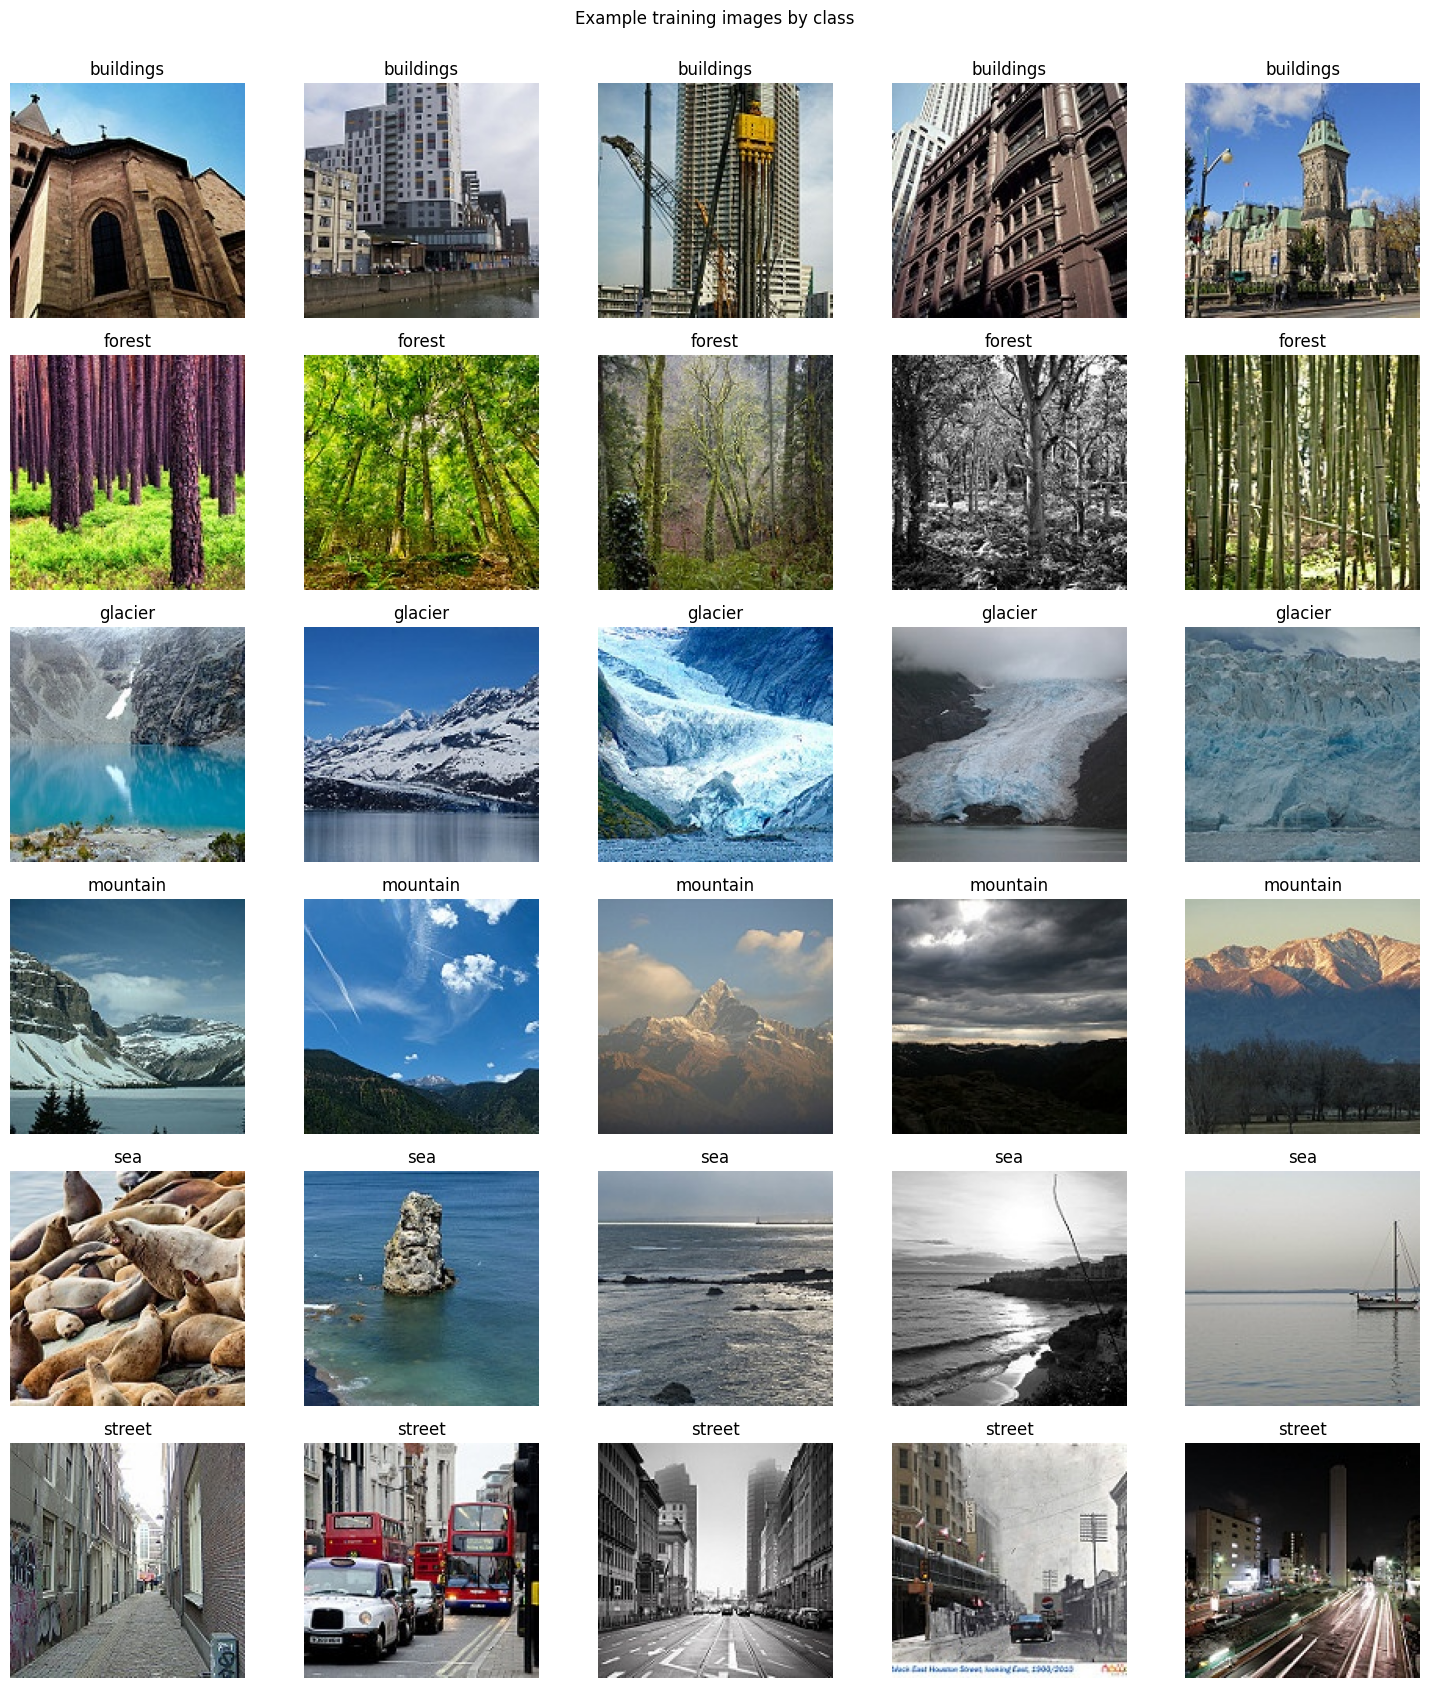

Valid images: 17044
Invalid/unreadable files: 0


In [5]:
if inspection.empty:
    raise ValueError("Inspection table is empty; fix dataset paths first.")

valid_eda = inspection[inspection["valid"]].copy()
valid_eda["size_mb"] = valid_eda["bytes"] / (1024 ** 2)
valid_eda["aspect_ratio"] = valid_eda["width"] / valid_eda["height"]

# A. Class distribution in labelled train and test splits
class_counts = inspection.groupby(["split", "label"]).size().reset_index(name="images")
plt.figure(figsize=(12, 5))
sns.barplot(data=class_counts, x="label", y="images", hue="split")
plt.title("Image counts by class and split")
plt.xlabel("Class"); plt.ylabel("Number of images")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

# B. Image dimensions and file sizes
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=valid_eda, x="width", hue="split", bins=30, element="step", ax=axes[0])
axes[0].set_title("Image width distribution")
sns.histplot(data=valid_eda, x="height", hue="split", bins=30, element="step", ax=axes[1])
axes[1].set_title("Image height distribution")
sns.histplot(data=valid_eda, x="size_mb", hue="split", bins=30, element="step", ax=axes[2])
axes[2].set_title("File size distribution (MB)")
plt.tight_layout(); plt.show()

# C. Aspect ratio by class
plt.figure(figsize=(11, 5))
sns.boxplot(data=valid_eda, x="label", y="aspect_ratio")
plt.title("Image aspect ratio by class")
plt.xlabel("Class"); plt.ylabel("Width / height")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

# D. Representative training images
classes_found = sorted(train_inspection["label"].dropna().unique())
if classes_found:
    fig, axes = plt.subplots(len(classes_found), 5, figsize=(15, 2.8 * len(classes_found)))
    axes = np.array(axes).reshape(len(classes_found), 5)
    rng = np.random.default_rng(42)
    for r, cls in enumerate(classes_found):
        paths = train_inspection.loc[
            (train_inspection["label"] == cls) & train_inspection["valid"], "path"
        ].tolist()
        chosen = rng.choice(paths, size=min(5, len(paths)), replace=False) if paths else []
        for c, ax in enumerate(axes[r]):
            ax.axis("off")
            if c < len(chosen):
                with Image.open(chosen[c]) as im:
                    ax.imshow(im.convert("RGB"))
                ax.set_title(cls)
    plt.suptitle("Example training images by class", y=1.002)
    plt.tight_layout(); plt.show()

print("Valid images:", len(valid_eda))
print("Invalid/unreadable files:", int((~inspection["valid"]).sum()))

4. Data cleaning and duplicate checks

What this cell does: builds a cleaning manifest that keeps only valid images with positive width, height and file size (no files are deleted). It then calculates a SHA-256 hash of each file. Identical files have identical hashes, so the cell lists exact duplicates and counts hashes that appear in both train and test. The manifest is saved to cleaned_image_manifest.csv so Spark can read it.

Why: if an image is in both train and test, the test score is too optimistic (data leakage). Identical images with different labels also confuse the model. This is the evidence used to build a cleaner training set for Model 2.

Limitation: a hash only finds exact duplicates, not near-duplicates (for example, the same scene photographed twice).

In [6]:
# Conservative cleaning manifest: no original files are deleted.
cleaned_manifest = inspection[
    inspection["valid"]
    & inspection["width"].gt(0)
    & inspection["height"].gt(0)
    & inspection["bytes"].gt(0)
].copy()

print("Files inspected:", len(inspection))
print("Valid images retained in manifest:", len(cleaned_manifest))
print("Invalid files excluded:", len(inspection) - len(cleaned_manifest))

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

hash_rows = []
for row in cleaned_manifest[["path", "split", "label"]].itertuples(index=False, name=None):
    path, split, label = row
    try:
        hash_rows.append({"path": path, "split": split, "label": label, "sha256": sha256_file(path)})
    except OSError as e:
        print("Could not hash:", path, e)

hash_table = pd.DataFrame(hash_rows)
if not hash_table.empty:
    duplicate_files = hash_table[hash_table.duplicated("sha256", keep=False)].sort_values("sha256")
    print("Files in exact duplicate groups:", len(duplicate_files))
    display(duplicate_files.head(30))
    split_counts = hash_table.groupby("sha256")["split"].nunique()
    print("Duplicate hashes shared across train/test:", int((split_counts > 1).sum()))

cleaned_manifest.to_csv("/content/cleaned_image_manifest.csv", index=False)
print("Saved /content/cleaned_image_manifest.csv")

Files inspected: 17044
Valid images retained in manifest: 17044
Invalid files excluded: 0
Files in exact duplicate groups: 56


,path,split,label,sha256
11759,/content/drive/MyDrive/archive (8)/seg_train/s...,train,street,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...
417,/content/drive/MyDrive/archive (8)/seg_train/s...,train,buildings,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...
4929,/content/drive/MyDrive/archive (8)/seg_train/s...,train,glacier,0dfad42c3489a935d2a0c56a32141d4de039ba31cccbf8...
4928,/content/drive/MyDrive/archive (8)/seg_train/s...,train,glacier,0dfad42c3489a935d2a0c56a32141d4de039ba31cccbf8...
4942,/content/drive/MyDrive/archive (8)/seg_train/s...,train,glacier,1bc37593ad4652c2f8a652f2de56eead06668a6394f585...
4943,/content/drive/MyDrive/archive (8)/seg_train/s...,train,glacier,1bc37593ad4652c2f8a652f2de56eead06668a6394f585...
16687,/content/drive/MyDrive/archive (8)/seg_test/se...,test,street,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...
382,/content/drive/MyDrive/archive (8)/seg_train/s...,train,buildings,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...
5871,/content/drive/MyDrive/archive (8)/seg_train/s...,train,glacier,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...
8434,/content/drive/MyDrive/archive (8)/seg_train/s...,train,mountain,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...


Duplicate hashes shared across train/test: 3
Saved /content/cleaned_image_manifest.csv


5. Spark analysis of the image metadata

Uses Apache Spark on the manifest saved in section 5 (`cleaned_image_manifest.csv`) and on `hash_table` from the same section.

What this cell does: starts a local Spark session, loads the manifest into a Spark DataFrame and runs four analyses: (1) class counts and percentages per split, (2) average, minimum and maximum dimensions per split, (3) the number of non-square images by class, and (4) duplicate groups by hash, including groups shared across splits and groups with conflicting labels.

Why: the assignment requires Spark in the analysis. Spark is used here for fast, structured aggregation of the metadata. It is not used for training, which the instructions allow.

In [7]:
%pip install -q pyspark

In [8]:
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.master("local[*]").appName("IntelImageEDA").getOrCreate()

# The manifest was saved in section 5 of the original notebook.
sdf = spark.read.csv("/content/cleaned_image_manifest.csv", header=True, inferSchema=True)
print("Rows in manifest:", sdf.count())
sdf.printSchema()

# 1. Class distribution with percentages per split
counts = sdf.groupBy("split", "label").count()
totals = counts.groupBy("split").agg(F.sum("count").alias("total"))
(counts.join(totals, "split")
       .withColumn("pct", F.round(100 * F.col("count") / F.col("total"), 1))
       .orderBy("split", "label")
       .show())

# 2. Dimensions and file size summary per split
(sdf.groupBy("split")
    .agg(F.count("*").alias("images"),
         F.round(F.avg("bytes"), 0).alias("avg_bytes"),
         F.min("height").alias("min_height"),
         F.max("height").alias("max_height"),
         F.round(F.avg("height"), 2).alias("avg_height"),
         F.min("width").alias("min_width"),
         F.max("width").alias("max_width"))
    .show())

# 3. Images that are not 150 x 150
non_square = sdf.filter(F.col("height") != F.col("width"))
print("Images that are not square:", non_square.count())
non_square.groupBy("label").count().orderBy("label").show()

# 4. Duplicate analysis with Spark (hash_table comes from section 5 of the original notebook)
hs = spark.createDataFrame(hash_table[["split", "label", "sha256"]])
dup_groups = (hs.groupBy("sha256")
                .agg(F.count("*").alias("files"),
                     F.countDistinct("split").alias("n_splits"),
                     F.countDistinct("label").alias("n_labels"))
                .filter("files > 1"))
print("Duplicate groups:", dup_groups.count())
print("Files inside duplicate groups:", dup_groups.agg(F.sum("files")).collect()[0][0])
print("Groups shared by train AND test (leakage):", dup_groups.filter("n_splits > 1").count())
print("Groups with conflicting labels:", dup_groups.filter("n_labels > 1").count())
dup_groups.filter("n_splits > 1 OR n_labels > 1").show(truncate=False)

Rows in manifest: 17044
root
 |-- split: string (nullable = true)
 |-- label: string (nullable = true)
 |-- path: string (nullable = true)
 |-- extension: string (nullable = true)
 |-- bytes: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- height: integer (nullable = true)
 |-- mode: string (nullable = true)
 |-- valid: boolean (nullable = true)
 |-- error: string (nullable = true)

+-----+---------+-----+-----+----+
|split|    label|count|total| pct|
+-----+---------+-----+-----+----+
| test|buildings|  437| 3000|14.6|
| test|   forest|  474| 3000|15.8|
| test|  glacier|  553| 3000|18.4|
| test| mountain|  525| 3000|17.5|
| test|      sea|  510| 3000|17.0|
| test|   street|  501| 3000|16.7|
|train|buildings| 2191|14044|15.6|
|train|   forest| 2271|14044|16.2|
|train|  glacier| 2414|14044|17.2|
|train| mountain| 2512|14044|17.9|
|train|      sea| 2274|14044|16.2|
|train|   street| 2382|14044|17.0|
+-----+---------+-----+-----+----+

+-----+------+---------+--------

 6. Model preparation and Feature selection

 Validate all six classes before making a subset

 What this cell does: builds a dictionary listing the readable image paths for each class in train and test, and prints the counts. It stops with an error if any training class has fewer than 1,750 readable images, or if any test class has none.

Why: the next step samples 1,750 images from each class, so I confirm enough clean images exist first.

In [9]:
if TRAIN_DIR is None or TEST_DIR is None:
    raise ValueError(
        "Could not locate both labelled train and test class directories. "
        "Check the folder audit and re-extract the original Kaggle ZIP."
    )

def valid_paths_by_class(split_dir):
    result = {}
    for cls in sorted(EXPECTED_CLASSES):
        folder = split_dir / cls
        paths = []
        if folder.exists():
            for p in folder.rglob("*"):
                if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                    try:
                        with Image.open(p) as im:
                            im.verify()
                        paths.append(p)
                    except Exception:
                        pass
        result[cls] = paths
    return result

train_files_by_class = valid_paths_by_class(TRAIN_DIR)
test_files_by_class = valid_paths_by_class(TEST_DIR)

print("Readable training images:")
for cls, files in train_files_by_class.items():
    print(f"{cls}: {len(files)}")
print("\nReadable test images:")
for cls, files in test_files_by_class.items():
    print(f"{cls}: {len(files)}")

if any(len(train_files_by_class[c]) < 1750 for c in EXPECTED_CLASSES):
    raise ValueError(
        "At least one training class has fewer than 1,750 readable images. "
        "Restore the complete Kaggle archive; do not substitute seg_pred images."
    )
if any(len(test_files_by_class[c]) == 0 for c in EXPECTED_CLASSES):
    raise ValueError(
        "At least one test class has zero readable images. Restore the complete labelled test set."
    )

Readable training images:
buildings: 2191
forest: 2271
glacier: 2414
mountain: 2512
sea: 2274
street: 2382

Readable test images:
buildings: 437
forest: 474
glacier: 553
mountain: 525
sea: 510
street: 501


Create a balanced 10,500-image training subset

What this cell does: sets the random seed to 42, then randomly picks 1,750 images from each class and copies them into a new folder on Colab's local disk. It prints the counts per class and the total.

Why: equal class counts stop a larger class dominating training. The fixed seed makes the sample repeatable. Local storage reads faster than Google Drive, which speeds up training. The official test set is not touched here.

In [10]:
# The subset is written to Colab local storage for faster reads.
# 1,750 images × 6 classes = 10,500 total.
SUBSET_ROOT = Path("/content/intel_subset_10500")
SUBSET_TRAIN_DIR = SUBSET_ROOT / "seg_train"
IMAGES_PER_CLASS = 1750
random.seed(42)

if SUBSET_ROOT.exists():
    shutil.rmtree(SUBSET_ROOT)
SUBSET_TRAIN_DIR.mkdir(parents=True, exist_ok=True)

for cls in sorted(EXPECTED_CLASSES):
    destination = SUBSET_TRAIN_DIR / cls
    destination.mkdir(parents=True, exist_ok=True)
    chosen = random.sample(train_files_by_class[cls], IMAGES_PER_CLASS)
    for source in chosen:
        shutil.copy2(source, destination / source.name)

subset_counts = {
    cls: sum(1 for p in (SUBSET_TRAIN_DIR / cls).iterdir() if p.is_file())
    for cls in sorted(EXPECTED_CLASSES)
}
print("Subset counts:", subset_counts)
print("Total subset images:", sum(subset_counts.values()))

Subset counts: {'buildings': 1750, 'forest': 1750, 'glacier': 1750, 'mountain': 1750, 'sea': 1750, 'street': 1750}
Total subset images: 10500


Load data at 96×96 and prepare training/validation sets

What this cell does: imports TensorFlow and checks for a GPU. It then loads the subset with image_dataset_from_directory, resizing every image to 96×96 and splitting it 80% training and 20% validation using the same seed so the two sets never overlap. The datasets are prefetched so loading overlaps with training.

Why: the CNN needs a fixed input size. The validation set lets me tune training and use early stopping without touching the test set.

Note: the "Training examples: 8400" and "Validation examples: 2100" lines are typed in by hand. They match the 80:20 split of 10,500 images.

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

IMG_SIZE = (96, 96)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    SUBSET_TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb"
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    SUBSET_TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb"
)

class_names = train_ds.class_names
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Training examples:", 8400)
print("Validation examples:", 2100)

TensorFlow: 2.21.0
GPU devices: []
Found 10500 files belonging to 6 classes.
Using 8400 files for training.
Found 10500 files belonging to 6 classes.
Using 2100 files for validation.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training examples: 8400
Validation examples: 2100


7. Train model / Model development

Build a lightweight CNN

In [12]:
tf.keras.utils.set_random_seed(42)

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),
    augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,134 (109.90 KB)

 Trainable params: 28,134 (109.90 KB)

 Non-trainable params: 0 (0.00 B)

Train with early stopping (maximum 8 epochs)

In [13]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/best_scene_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)
elapsed = time.time() - start_time
print(f"Training time: {elapsed / 60:.1f} minutes")

Epoch 1/8
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.3037 - loss: 1.5668
Epoch 1: val_loss improved from None to 1.18849, saving model to /content/best_scene_cnn.keras

Epoch 1: finished saving model to /content/best_scene_cnn.keras
263/263 ━━━━━━━━━━━━━━━━━━━━ 98s 362ms/step - accuracy: 0.3839 - loss: 1.4063 - val_accuracy: 0.4805 - val_loss: 1.1885 - learning_rate: 0.0010
Epoch 2/8
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.4583 - loss: 1.2309
Epoch 2: val_loss improved from 1.18849 to 1.12335, saving model to /content/best_scene_cnn.keras

Epoch 2: finished saving model to /content/best_scene_cnn.keras
263/263 ━━━━━━━━━━━━━━━━━━━━ 95s 362ms/step - accuracy: 0.4875 - loss: 1.1881 - val_accuracy: 0.5581 - val_loss: 1.1234 - learning_rate: 0.0010
Epoch 3/8
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - accuracy: 0.5333 - loss: 1.1206
Epoch 3: val_loss improved from 1.12335 to 1.03085, saving model to /content/best_scene_cnn.keras

Epoch 3: finished saving mode

Plot training history

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.383929,1.406306,0.480476,1.188488,0.00100
1,0.487500,1.188149,0.558095,1.123353,0.00100
2,0.541786,1.101244,0.590000,1.030845,0.00100
3,0.573214,1.048852,0.577143,1.113923,0.00100
4,0.615595,0.974892,0.640000,0.908132,0.00050
5,0.630476,0.958037,0.654286,0.902799,0.00050
6,0.642976,0.924054,0.624286,0.971741,0.00050
7,0.656667,0.902372,0.675714,0.854031,0.00025


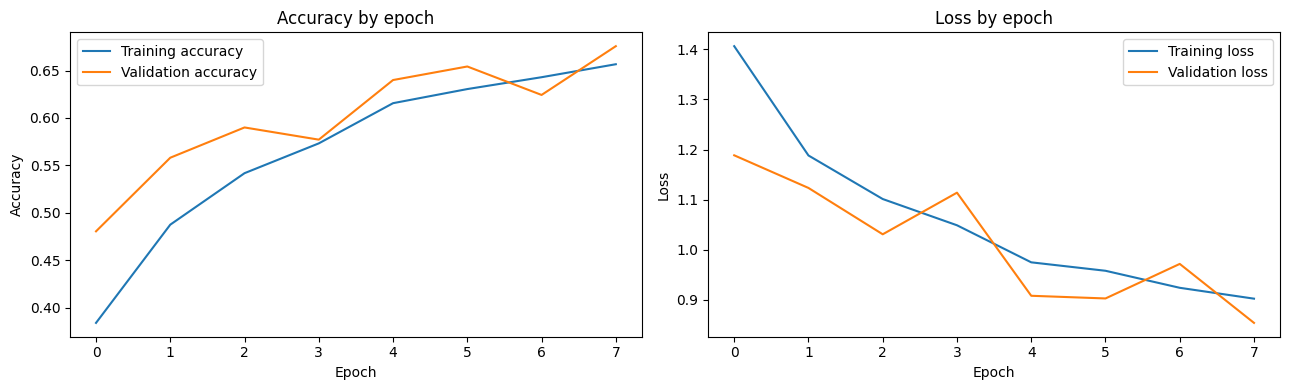

In [14]:
history_df = pd.DataFrame(history.history)
display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy by epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss by epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout(); plt.show()

8. Evaluation and interpretation of the model

Load the official test set and evaluate

Found 3000 files belonging to 6 classes.
Test classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step
Test accuracy: 0.6717
Macro F1: 0.6689
Weighted F1: 0.6702

Classification report:
              precision    recall  f1-score   support

   buildings     0.4700    0.5195    0.4935       437
      forest     0.8466    0.9198    0.8817       474
     glacier     0.7576    0.5823    0.6585       553
    mountain     0.6764    0.5733    0.6206       525
         sea     0.6761    0.6588    0.6673       510
      street     0.6189    0.7844    0.6919       501

    accuracy                         0.6717      3000
   macro avg     0.6743    0.6730    0.6689      3000
weighted avg     0.6785    0.6717    0.6702      3000



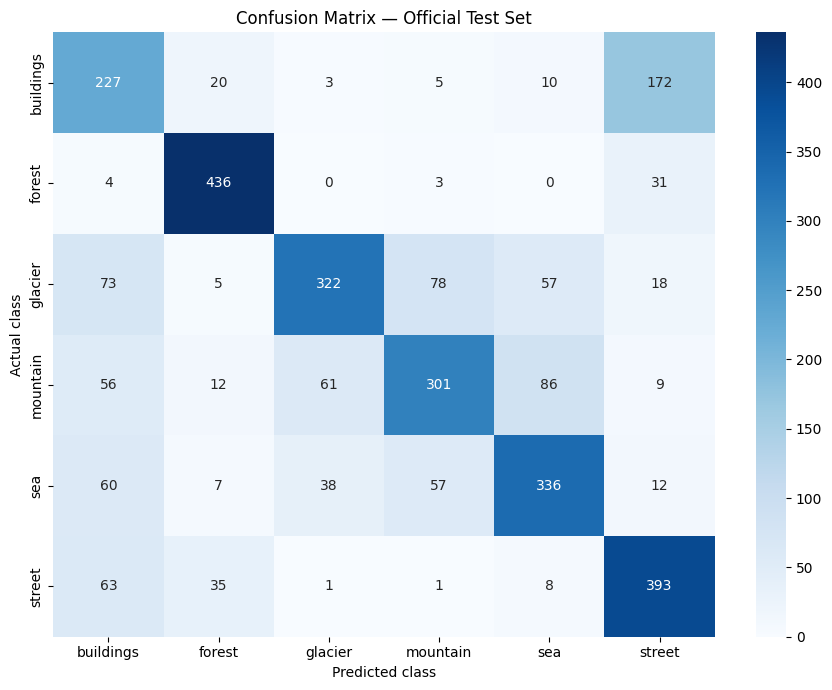

In [15]:
# Official test set stays separate from training and validation.
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int",
    color_mode="rgb"
)
test_class_names = test_ds.class_names
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)
print("Test classes:", test_class_names)

if test_class_names != class_names:
    raise ValueError(f"Class order differs: train={class_names}, test={test_class_names}")

y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 4))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix — Official Test Set")
plt.tight_layout()
plt.show()

Predict one test image

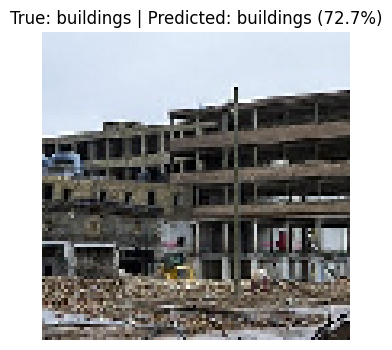

In [16]:
import random
test_image_paths = [
    p for cls in sorted(EXPECTED_CLASSES)
    for p in (TEST_DIR / cls).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]
sample_path = random.choice(test_image_paths)

img = tf.keras.utils.load_img(sample_path, target_size=IMG_SIZE)
arr = tf.keras.utils.img_to_array(img)
probs = model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]
pred_idx = int(np.argmax(probs))

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.axis("off")
plt.title(f"True: {sample_path.parent.name} | Predicted: {class_names[pred_idx]} ({probs[pred_idx]:.1%})")
plt.show()

Building Model 2

Clean duplicates and build a balanced subset for Model 2

1. Remove training images whose hash also appears in the test set (stops leakage).
2. Remove training images whose identical copies carry different labels (label noise).
3. Keep one copy of the remaining exact duplicates.

The official test set is unchanged (all 3,000 images), so Model 1 and Model 2 are compared on the same test data.

In [17]:
train_h = hash_table[hash_table["split"] == "train"].copy()
test_hashes = set(hash_table.loc[hash_table["split"] == "test", "sha256"])

n0 = len(train_h)
train_h = train_h[~train_h["sha256"].isin(test_hashes)]
n1 = len(train_h)

label_counts = train_h.groupby("sha256")["label"].nunique()
conflicting = set(label_counts[label_counts > 1].index)
train_h = train_h[~train_h["sha256"].isin(conflicting)]
n2 = len(train_h)

train_h = train_h.drop_duplicates("sha256", keep="first")
n3 = len(train_h)

print(f"Training images before cleaning: {n0}")
print(f"After removing train/test leakage: {n1}  (removed {n0 - n1})")
print(f"After removing conflicting labels: {n2}  (removed {n1 - n2})")
print(f"After keeping one copy of duplicates: {n3}  (removed {n2 - n3})")
print(train_h["label"].value_counts().sort_index())

CLEAN_ROOT = Path("/content/intel_subset_clean")
CLEAN_TRAIN_DIR = CLEAN_ROOT / "seg_train"
IMAGES_PER_CLASS = 1750
random.seed(42)

if CLEAN_ROOT.exists():
    shutil.rmtree(CLEAN_ROOT)

for cls in sorted(EXPECTED_CLASSES):
    paths = train_h.loc[train_h["label"] == cls, "path"].tolist()
    assert len(paths) >= IMAGES_PER_CLASS, f"{cls} has only {len(paths)} clean images"
    dest = CLEAN_TRAIN_DIR / cls
    dest.mkdir(parents=True, exist_ok=True)
    for src in random.sample(paths, IMAGES_PER_CLASS):
        shutil.copy2(src, dest / Path(src).name)

clean_counts = {c: len(list((CLEAN_TRAIN_DIR / c).iterdir())) for c in sorted(EXPECTED_CLASSES)}
print("Clean subset counts:", clean_counts, "| total:", sum(clean_counts.values()))

Training images before cleaning: 14044
After removing train/test leakage: 14041  (removed 3)
After removing conflicting labels: 14021  (removed 20)
After keeping one copy of duplicates: 14006  (removed 15)
label
buildings    2187
forest       2269
glacier      2398
mountain     2504
sea          2272
street       2376
Name: count, dtype: int64
Clean subset counts: {'buildings': 1750, 'forest': 1750, 'glacier': 1750, 'mountain': 1750, 'sea': 1750, 'street': 1750} | total: 10500


Model 2: retrain with different parameters

| Setting | Model 1 | Model 2 |
|---|---|---|
| Input size | 96 x 96 | 128 x 128 |
| Filters per block | 16 / 32 / 64 | 32 / 64 / 128 |
| BatchNormalization | none | after every convolution |
| Dense layer / dropout | 64 / 0.3 | 128 / 0.4 |
| Augmentation | flip, rotation 0.03 | flip, rotation 0.05, zoom 0.1 |
| Maximum epochs | 8 | 20 (early stopping patience 4) |
| Training data | 10,500 images, duplicates kept | 10,500 images, leakage and conflicting duplicates removed |



In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

IMG_SIZE2 = (128, 128)
BATCH_SIZE2 = 32
SEED = 42
print("GPU devices:", tf.config.list_physical_devices("GPU"))

train_ds2 = tf.keras.utils.image_dataset_from_directory(
    CLEAN_TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE2, batch_size=BATCH_SIZE2, label_mode="int", color_mode="rgb")
val_ds2 = tf.keras.utils.image_dataset_from_directory(
    CLEAN_TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE2, batch_size=BATCH_SIZE2, label_mode="int", color_mode="rgb")

class_names2 = train_ds2.class_names
assert class_names2 == class_names, "Class order changed"
train_ds2 = train_ds2.prefetch(tf.data.AUTOTUNE)
val_ds2 = val_ds2.prefetch(tf.data.AUTOTUNE)

def conv_block(filters):
    return [
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),
    ]

tf.keras.utils.set_random_seed(42)

augmentation2 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="augmentation2")

model2 = models.Sequential(
    [layers.Input(shape=(*IMG_SIZE2, 3)), augmentation2, layers.Rescaling(1.0 / 255)]
    + conv_block(32) + conv_block(64) + conv_block(128)
    + [layers.GlobalAveragePooling2D(),
       layers.Dense(128, activation="relu"),
       layers.Dropout(0.4),
       layers.Dense(len(class_names2), activation="softmax")],
    name="scene_cnn_v2",
)

model2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model2.summary()

GPU devices: []
Found 10500 files belonging to 6 classes.
Using 8400 files for training.
Found 10500 files belonging to 6 classes.
Using 2100 files for validation.


Model: "scene_cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation2 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,206 (434.40 KB)

 Trainable params: 110,758 (432.65 KB)

 Non-trainable params: 448 (1.75 KB)

In [19]:
import time
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks2 = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ModelCheckpoint("/content/best_scene_cnn_v2.keras", monitor="val_loss",
                    save_best_only=True, verbose=1),
]

start = time.time()
history2 = model2.fit(train_ds2, validation_data=val_ds2, epochs=20,
                      callbacks=callbacks2, verbose=1)
print(f"Training time: {(time.time() - start) / 60:.1f} minutes")
print("Epochs run:", len(history2.history["loss"]))


Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4901 - loss: 1.2743
Epoch 1: val_loss improved from None to 2.19507, saving model to /content/best_scene_cnn_v2.keras

Epoch 1: finished saving model to /content/best_scene_cnn_v2.keras
263/263 ━━━━━━━━━━━━━━━━━━━━ 522s 2s/step - accuracy: 0.5544 - loss: 1.1182 - val_accuracy: 0.2143 - val_loss: 2.1951 - learning_rate: 0.0010
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6145 - loss: 0.9811
Epoch 2: val_loss improved from 2.19507 to 1.29245, saving model to /content/best_scene_cnn_v2.keras

Epoch 2: finished saving model to /content/best_scene_cnn_v2.keras
263/263 ━━━━━━━━━━━━━━━━━━━━ 559s 2s/step - accuracy: 0.6340 - loss: 0.9418 - val_accuracy: 0.4876 - val_loss: 1.2925 - learning_rate: 0.0010
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6687 - loss: 0.8663
Epoch 3: val_loss did not improve from 1.29245
263/263 ━━━━━━━━━━━━━━━━━━━━ 599s 2s/step - accuracy: 0.6815 - loss: 0.8413 - v

Evaluate Model 2 and compare with Model 1

The Model 1 numbers in the comparison table are copied from this notebook's section 12 output.

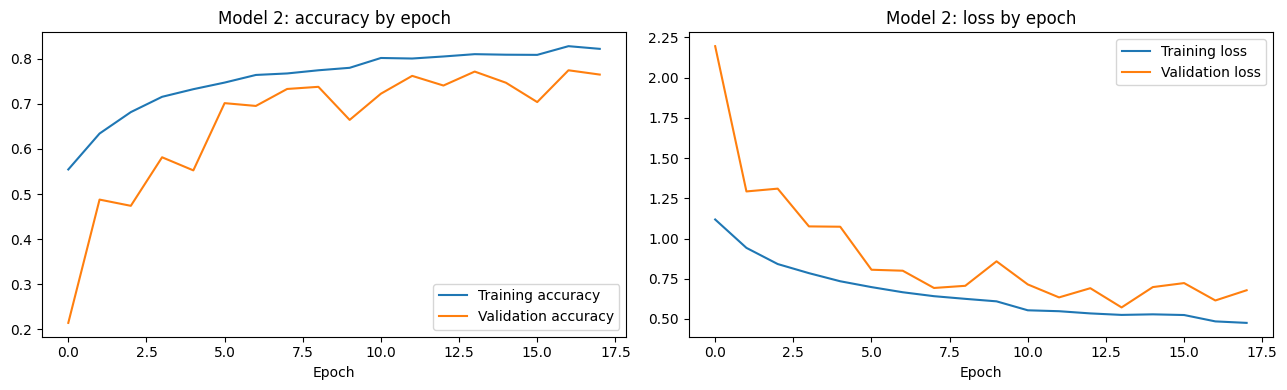

Found 3000 files belonging to 6 classes.
94/94 ━━━━━━━━━━━━━━━━━━━━ 39s 409ms/step
Model 2 test accuracy: 0.7597
Model 2 macro F1: 0.7583
Model 2 weighted F1: 0.7508

              precision    recall  f1-score   support

   buildings     0.7785    0.7963    0.7873       437
      forest     0.9700    0.9557    0.9628       474
     glacier     0.9548    0.3436    0.5053       553
    mountain     0.5240    0.9371    0.6721       525
         sea     0.8889    0.7059    0.7869       510
      street     0.8029    0.8703    0.8352       501

    accuracy                         0.7597      3000
   macro avg     0.8199    0.7682    0.7583      3000
weighted avg     0.8196    0.7597    0.7508      3000



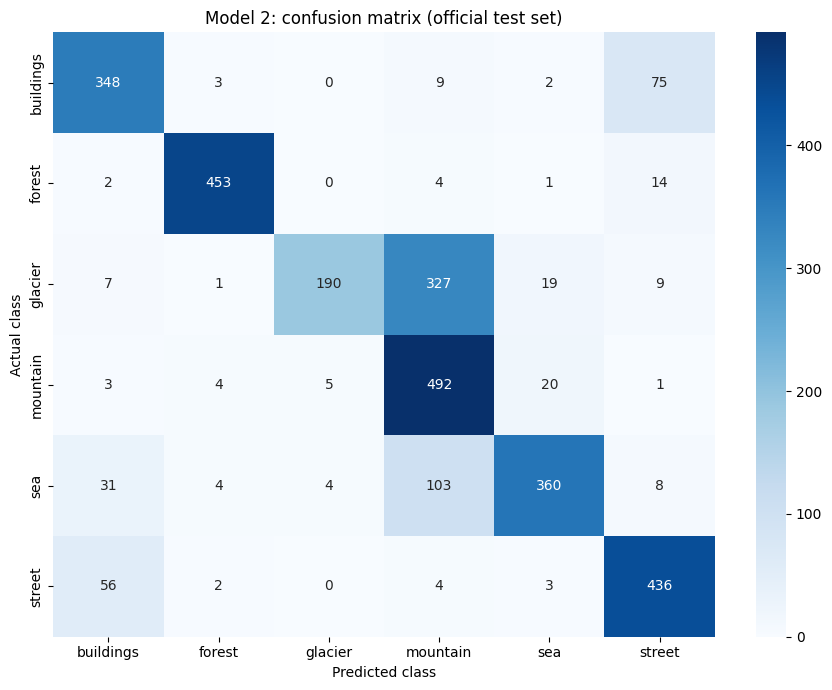

,Metric,Model 1,Model 2
0,Input size,96 x 96,128 x 128
1,Filters per block,16 / 32 / 64,32 / 64 / 128
2,Max epochs,8,20
3,Epochs run,8,18
4,Trainable parameters,28134,111206
5,Best validation accuracy,0.6757,0.7743
6,Test accuracy,0.6717,0.7597
7,Macro F1,0.6689,0.7583
8,F1 buildings,0.4935,0.7873
9,F1 street,0.6919,0.8352


In [20]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_recall_fscore_support

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history2.history["accuracy"], label="Training accuracy")
axes[0].plot(history2.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Model 2: accuracy by epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history2.history["loss"], label="Training loss")
axes[1].plot(history2.history["val_loss"], label="Validation loss")
axes[1].set_title("Model 2: loss by epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

# Official test set at Model 2's input size (same 3,000 images as Model 1)
test_ds2 = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE2, batch_size=BATCH_SIZE2,
    shuffle=False, label_mode="int", color_mode="rgb")
assert test_ds2.class_names == class_names2
test_ds2 = test_ds2.prefetch(tf.data.AUTOTUNE)

y_true2 = np.concatenate([labels.numpy() for _, labels in test_ds2], axis=0)
y_pred2 = np.argmax(model2.predict(test_ds2, verbose=1), axis=1)

test_acc2 = accuracy_score(y_true2, y_pred2)
macro_f1_2 = f1_score(y_true2, y_pred2, average="macro", zero_division=0)
weighted_f1_2 = f1_score(y_true2, y_pred2, average="weighted", zero_division=0)
print("Model 2 test accuracy:", round(test_acc2, 4))
print("Model 2 macro F1:", round(macro_f1_2, 4))
print("Model 2 weighted F1:", round(weighted_f1_2, 4))
print()
print(classification_report(y_true2, y_pred2, target_names=class_names2, digits=4, zero_division=0))

cm2 = confusion_matrix(y_true2, y_pred2)
plt.figure(figsize=(9, 7))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names2, yticklabels=class_names2)
plt.xlabel("Predicted class"); plt.ylabel("Actual class")
plt.title("Model 2: confusion matrix (official test set)")
plt.tight_layout(); plt.show()

# Comparison table for report section 8.
# Model 1 numbers are copied from your original notebook outputs.
f1_per_class2 = precision_recall_fscore_support(y_true2, y_pred2, zero_division=0)[2]
comparison = pd.DataFrame({
    "Metric": ["Input size", "Filters per block", "Max epochs", "Epochs run",
               "Trainable parameters", "Best validation accuracy", "Test accuracy",
               "Macro F1", "F1 buildings", "F1 street"],
    "Model 1": ["96 x 96", "16 / 32 / 64", 8, 8, 28134, 0.6757, 0.6717, 0.6689, 0.4935, 0.6919],
    "Model 2": [f"{IMG_SIZE2[0]} x {IMG_SIZE2[1]}", "32 / 64 / 128", 20,
                len(history2.history["loss"]), model2.count_params(),
                round(max(history2.history["val_accuracy"]), 4), round(test_acc2, 4),
                round(macro_f1_2, 4),
                round(f1_per_class2[class_names2.index("buildings")], 4),
                round(f1_per_class2[class_names2.index("street")], 4)],
})
display(comparison)